# Outlier Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Small sample dataset with intentional unusual and invalid entries
df = pd.DataFrame({
    "Customer_ID": range(101, 116),
    "Age": [22, 25, 28, 30, 33, 35, 37, 40, 42, 45, 48, 50, 52, 29, 250],
    "Monthly_Spend": [180, 200, 220, 230, 250, 270, 290, 310, 330, 350, 370, 390, 410, 2500, 450],
    "Orders": [2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 7, 8, 8, 30, 5],
    "Customer_Type": ["Regular"] * 13 + ["Wholesale", "Regular"]
})
print(df.to_string(index=False))

 Customer_ID  Age  Monthly_Spend  Orders Customer_Type
         101   22            180       2       Regular
         102   25            200       3       Regular
         103   28            220       3       Regular
         104   30            230       4       Regular
         105   33            250       4       Regular
         106   35            270       5       Regular
         107   37            290       5       Regular
         108   40            310       6       Regular
         109   42            330       6       Regular
         110   45            350       7       Regular
         111   48            370       7       Regular
         112   50            390       8       Regular
         113   52            410       8       Regular
         114   29           2500      30     Wholesale
         115  250            450       5       Regular


# 1. What is an Outlier?
# Definition
An outlier is an observation that differs noticeably from most other values. It may be a mistake or a genuine rare case. Statistical rules flag unusual values but do not prove they are incorrect.

# Business Example
A store notices a customer spending far more than others. The transaction may belong to a wholesale customer, not a recording error.

# AI/ML Use
Outliers can distort model training and summary statistics. We inspect them before deciding whether to retain, correct, transform, or exclude them.

# Python Example

In [2]:
print(df.loc[df["Monthly_Spend"] > 1000, ["Customer_ID", "Monthly_Spend", "Customer_Type"]])

    Customer_ID  Monthly_Spend Customer_Type
13          114           2500     Wholesale


# Explanation
The result highlights an unusually high-spending customer. The Wholesale label gives a plausible explanation, but it still needs verification.

# 2. Why Outliers Occur
# Definition
Outliers can result from typing errors, measurement problems, rare events, genuine extreme behavior, or changes in the underlying process. Their causes must be investigated rather than assumed.

# Business Example
A staff member enters age 250 instead of 25. A large order from a wholesale customer, however, may be valid.

# AI/ML Use
Understanding the cause prevents incorrect deletion of useful training examples. Invalid values should be corrected using trustworthy records.

# Python Example

In [3]:
print(df.loc[(df["Age"] > 120) | (df["Monthly_Spend"] > 1000), ["Customer_ID", "Age", "Monthly_Spend", "Customer_Type"]])

    Customer_ID  Age  Monthly_Spend Customer_Type
13          114   29           2500     Wholesale
14          115  250            450       Regular


# Explanation
Age 250 is implausible for a human and should be checked against the source. The large spending amount may be legitimate.

# 3. Types of Outliers
# Definition
Common types are global or point outliers, contextual outliers, and collective outliers. A global outlier is extreme overall; a contextual outlier is unusual only in a particular setting; a collective outlier is an unusual group or pattern.

# Business Example
A single huge payment is a point outlier. High electricity use at midnight may be contextual. A sequence of unusual withdrawals may be collective.

# AI/ML Use
Different outlier types need different detection strategies. Context and sequence information can matter as much as the numerical magnitude.

# Python Example

In [4]:
print("Point candidate:")
print(df.nlargest(1, "Monthly_Spend")[["Customer_ID", "Monthly_Spend"]])
print("Context candidate (regular customers):")
print(df.loc[(df["Customer_Type"] == "Regular") & (df["Age"] > 120), ["Customer_ID", "Age"]])

Point candidate:
    Customer_ID  Monthly_Spend
13          114           2500
Context candidate (regular customers):
    Customer_ID  Age
14          115  250


# Explanation
The spending peak is a point-outlier candidate. The impossible age is suspicious within the customer context. Collective outliers would require sequential data.


# 4. Univariate Outliers
# Definition
Univariate analysis checks unusual values in one feature at a time. The IQR rule and Z-score are common screening methods. A value can be unusual in one column while normal in others.

# Business Example
A business examines only the Monthly_Spend column to locate unusually large purchases.

# AI/ML Use
This helps detect extreme input values before scaling or model training. One-variable checks may miss unusual combinations of otherwise normal values.

# Python Example

In [5]:
q1, q3 = df["Monthly_Spend"].quantile([0.25, 0.75])
iqr = q3 - q1
print(df.loc[(df["Monthly_Spend"] < q1 - 1.5*iqr) | (df["Monthly_Spend"] > q3 + 1.5*iqr), ["Customer_ID", "Monthly_Spend"]])

    Customer_ID  Monthly_Spend
13          114           2500


# Explanation
The IQR method flags values far outside the central spread. These are candidates for review, not automatic removals.

# 5. Multivariate Outliers
# Definition
Multivariate outliers are unusual combinations of two or more features. Individual values may look normal separately but form a rare combination together. Domain knowledge helps interpret these cases.

# Business Example
A customer with a moderate number of orders but extremely high spending might be unusual compared with other customers.

# AI/ML Use
Joint-feature checks can reveal unusual records that single-column checks miss. They can also highlight meaningful customer segments.

# Python Example

    Customer_ID  Orders  Monthly_Spend Customer_Type
13          114      30           2500     Wholesale
14          115       5            450       Regular
12          113       8            410       Regular
11          112       8            390       Regular


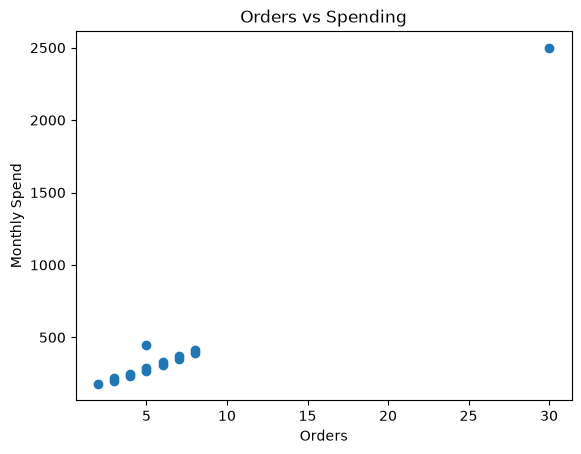

In [6]:
print(df[["Customer_ID", "Orders", "Monthly_Spend", "Customer_Type"]].sort_values("Monthly_Spend", ascending=False).head(4))
plt.scatter(df["Orders"], df["Monthly_Spend"])
plt.xlabel("Orders"); plt.ylabel("Monthly Spend"); plt.title("Orders vs Spending"); plt.show()

# Explanation
The scatter plot reveals whether a customer’s spending is unusual relative to order count. The wholesale record deserves contextual review.

# 6. IQR Method
# Definition
The Interquartile Range (IQR) is Q3 minus Q1. A common rule flags values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. It is resistant to extreme values because it uses quartiles.

# Business Example
A retail analyst checks which monthly purchases fall far beyond the usual spending range.

# AI/ML Use
IQR is useful for skewed or non-normal features as a first screening step. It can still flag valid rare transactions.

# Python Example

In [7]:
s = df["Monthly_Spend"]
q1, q3 = s.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print("Lower:", lower, "Upper:", upper)
print(df.loc[(s < lower) | (s > upper), ["Customer_ID", "Monthly_Spend"]])

Lower: 30.0 Upper: 590.0
    Customer_ID  Monthly_Spend
13          114           2500


# Explanation
Values outside the calculated fences are flagged. Compare them with the customer type and transaction records before acting.

# 7. Z-Score Method
# Definition
A Z-score tells how many standard deviations a value is from the mean. A common screening threshold is an absolute Z-score above 3. Mean and standard deviation are themselves affected by extreme values.

# Business Example
An analyst compares customer spending with the overall average to identify unusually distant observations.

# AI/ML Use
Z-scores can be useful when the distribution is roughly symmetric. For heavily skewed data, consider robust methods instead.

# Python Example

In [8]:
s = df["Monthly_Spend"]
z = (s - s.mean()) / s.std(ddof=0)
print(df.loc[z.abs() > 3, ["Customer_ID", "Monthly_Spend"]].assign(Z_Score=z[z.abs() > 3].round(2)))

    Customer_ID  Monthly_Spend  Z_Score
13          114           2500      3.7


# Explanation
A large absolute Z-score indicates distance from the average. It does not by itself establish that a record is wrong.

# 8. Box Plot
# Definition
A box plot displays the median, quartiles, whiskers, and points beyond the whiskers. It summarizes the spread of a single numerical variable. The points beyond whiskers are potential outliers.

# Business Example
A manager uses a box plot to compare typical customer spending with unusual purchases.

# AI/ML Use
Box plots provide a quick visual check before feature scaling or transformation. Interpret flagged points using business context.

# Python Example

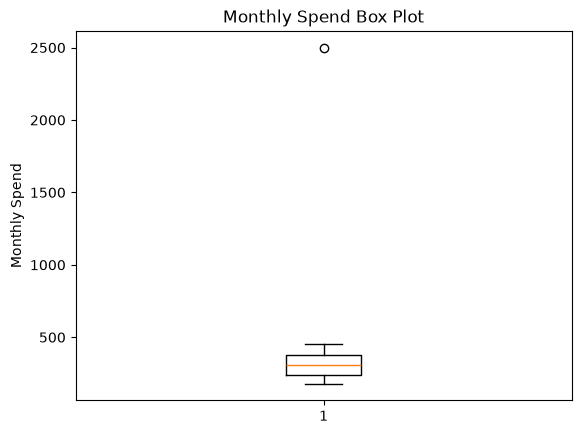

In [9]:
plt.boxplot(df["Monthly_Spend"].dropna())
plt.ylabel("Monthly Spend")
plt.title("Monthly Spend Box Plot")
plt.show()

# Explanation
The separate high point indicates unusual spending. The plot alone cannot tell whether it is an error or a wholesale purchase.

# 9. Scatter Plot
# Definition
A scatter plot displays two numerical features as points. It helps reveal relationships, clusters, and observations that lie away from the main pattern. It is useful for investigating unusual combinations.

# Business Example
A store compares number of orders with monthly spending to spot customers who spend much more than expected.

# AI/ML Use
Scatter plots can reveal multivariate outlier candidates before feature engineering or modeling. They do not automatically establish causality.

# Python Example

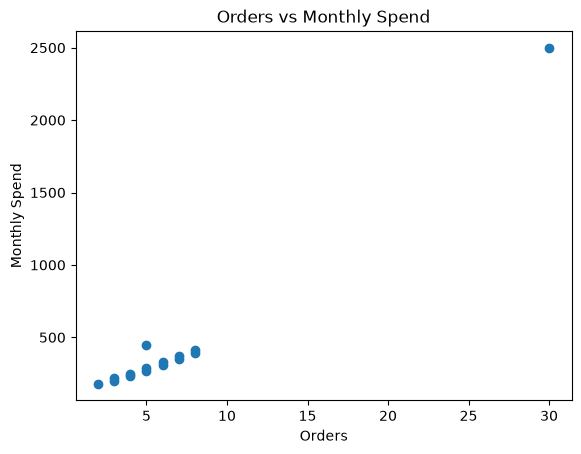

In [10]:
plt.scatter(df["Orders"], df["Monthly_Spend"])
plt.xlabel("Orders")
plt.ylabel("Monthly Spend")
plt.title("Orders vs Monthly Spend")
plt.show()

# Explanation
Most customers form a cluster, while the wholesale customer appears apart. Investigate the reason before changing the record.

# Review Detected Outliers – Decisions and Reasoning
Detection does not mean deletion. Check source records, business context, and whether a value is possible before making a decision.

# 10. Is it a genuine observation?
# Definition
A genuine observation is supported by a real source record and valid business context. A high purchase can be genuine even if it is statistically unusual.

# Business Example
A wholesale customer makes a bulk purchase that exceeds the usual retail spending.

# AI/ML Use
Genuine rare observations may be important for predicting high-value customers. Removing them could weaken model performance.

# Python Example

In [12]:
print(df.loc[df["Customer_ID"] == 114, ["Customer_ID", "Monthly_Spend", "Customer_Type"]])

    Customer_ID  Monthly_Spend Customer_Type
13          114           2500     Wholesale


# Explanation
Customer 114 has high spending and a Wholesale label. Treat it as a possible genuine observation, pending transaction verification.

# 11. Is it a data-entry error?
# Definition
A data-entry error is a value recorded incorrectly through typing, import, or measurement. Impossible values provide strong reasons to investigate. Do not guess the corrected value without evidence.

# Business Example
An employee accidentally enters age 250 rather than a realistic age.

# AI/ML Use
Incorrect training values can distort feature distributions and model decisions. Correct from a trusted source or mark missing when correction is unavailable.

# Python Example

In [13]:
print(df.loc[df["Age"] > 120, ["Customer_ID", "Age"]])

    Customer_ID  Age
14          115  250


# Explanation
Age 250 is invalid for a human. Verify the source; if no correction is available, mark the value missing instead of inventing an age.

# 12. Is it an unusual but valid observation?
# Definition
An unusual but valid observation is rare yet plausible within the domain. Its rarity is not enough reason to remove it. Segment information often explains it.

# Business Example
A wholesale buyer orders much more than a typical retail buyer.

# AI/ML Use
Keeping valid extremes helps models learn real variation. Consider separate segment analysis if customer types behave differently.

# Python Example

In [14]:
print(df.groupby("Customer_Type")["Monthly_Spend"].agg(["count", "median", "max"]))

               count  median   max
Customer_Type                     
Regular           14   300.0   450
Wholesale          1  2500.0  2500


# Explanation
The wholesale segment has different spending behavior. The record should be checked but not automatically deleted.

# 13. Should it be removed?
# Definition
Removal is appropriate when a record is demonstrably invalid, duplicated incorrectly, or outside the defined study population. A statistical flag alone is insufficient.

# Business Example
A company excludes a test transaction that was never a real sale, after confirming its origin.

# AI/ML Use
Unjustified deletion can bias the training data. Document the reason and compare results before and after removal.

# Python Example

In [15]:
invalid_age = df["Age"] > 120
print("Rows needing verification:", invalid_age.sum())
print("Rows kept for now:", len(df))

Rows needing verification: 1
Rows kept for now: 15


# Explanation
The impossible age is flagged, but no row is removed automatically. Correction or exclusion requires confirmation.

# 14. Should it be transformed?
# Definition
Transformation changes a feature’s scale to reduce the influence of extreme magnitudes. A log transform can help with nonnegative, right-skewed values. Transformation does not fix invalid records.

# Business Example
A retailer log-transforms purchase amounts so a few large transactions do not dominate the feature scale.

# AI/ML Use
Some ML models benefit from transformed skewed inputs. Fit transformations using training data and apply consistently to validation and test data.

# Python Example

In [16]:
df["Log_Spend"] = np.log1p(df["Monthly_Spend"])
print(df[["Monthly_Spend", "Log_Spend"]].tail(3))

    Monthly_Spend  Log_Spend
12            410   6.018593
13           2500   7.824446
14            450   6.111467


# Explanation
The transformed values compress large spending amounts while preserving their ordering. The original spending column remains available.

# 15. Should it be retained?
# Definition
Retention is appropriate when a value is valid and relevant to the prediction task. Keeping unusual cases preserves important variation in the population.

# Business Example
A bank keeps verified large transactions because fraud or premium-customer behavior may involve rare amounts.

# AI/ML Use
Rare valid examples can improve generalization to unusual real-world cases. Monitor model performance across both typical and extreme records.

# Python Example



In [17]:
verified_candidate = df.loc[df["Customer_ID"] == 114, ["Customer_ID", "Monthly_Spend", "Customer_Type"]]
print(verified_candidate)
print("Decision: retain provisionally; verify transaction record first.")


    Customer_ID  Monthly_Spend Customer_Type
13          114           2500     Wholesale
Decision: retain provisionally; verify transaction record first.


# Explanation
The wholesale record is retained provisionally because it is plausible. Final retention depends on verification and modeling goals.

# Documented Decision Summary